# 04 Exploratory data analysis

**Sales are not demand.** The data record units sold, not demand. A day without a sales record may mean that no customer bought the product, that it was out of stock, that it was not on display or that the record is missing, and the dataset has no inventory or shelf-availability information to tell these cases apart. Sales are therefore censored demand: stock-outs lower observed sales, and the zeros added to the grid are assumed zero-sales days. This affects the demand classification (intermittency may be overstated), the lag features and the forecast errors, so all results describe observed sales, not true demand.

**Scope of the results.** All analyses use a development subset of 10 stores in three provinces (Pichincha, Guayas, Azuay) that were open from the start of the data, and 15% of the products in each family. The results describe this subset of the Favorita chain, not the whole chain and not the Ecuadorian market. The baselines are repeated on all 54 stores to check how far the subset results carry over.

**Terminology.** In this notebook, "demand pattern" and "demand class" refer to patterns of observed sales. Observed sales are a proxy for demand and may understate it when products were out of stock or not on display. Zeros added to the grid are called zero-filled or assumed zero-sales days, never confirmed zero demand.

## 1. Series profile: intermittency (ADI, CV²) and ABC-XYZ

**Purpose.** Describe how each store-item series behaves (how often it sells, how variable the sales are, how much it contributes) so that the later charts and baselines can be read by segment. This answers the research question on intermittent demand.

**Method.**
- Only the **train split**, store open (no-record days removed), is used, so the segments do not depend on validation or test.
- **ADI** is the average number of days between sales (days / days with a sale). **CV²** is the squared coefficient of variation of the non-zero sales. The standard cut-offs of Syntetos and Boylan (ADI 1.32, CV² 0.49) give four classes: *smooth*, *erratic*, *intermittent*, *lumpy*. Series with fewer than 28 days or fewer than 2 sales are labelled "short history".
- **ABC** is a quantity-based proxy: series are ranked by total units sold (items and kilograms are added together and there are no prices, so this is not revenue or value); A = series whose cumulative share of the quantity is at most 80%, B = up to 95%, C = the rest.
- **XYZ** is a descriptive diagnostic based on the variability of daily sales, including zero-filled days (CV below 0.5 = X, below 1 = Y, otherwise Z). On daily data it leaves class X almost empty, and it measures something different from CV² of the non-zero sales, so it does not replace ADI-CV². These cut-offs are conventions, not rules of the data.

**Output.** `features/series_profile.parquet` (one row per series) and the class and ABC-XYZ tables below.

**Limitation.** Based on a 10-store, 607-item subset. Zeros filled into the grid count as "no sale", but the data cannot tell a lack of demand from a stock-out, so intermittency may be overstated.

In [28]:
import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
ADI_CUT, CV2_CUT = 1.32, 0.49     # Syntetos-Boylan cut-offs
MIN_DAYS = 28                     # shorter series are not classified

cols = ["store_nbr", "item_nbr", "family", "perishable", "unit_sales", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]].copy()      # train only, store open
tr["family"] = tr["family"].astype(str)
tr["nz"] = tr["unit_sales"] > 0
tr["y_nz"] = tr["unit_sales"].where(tr["nz"])

g = tr.groupby(["store_nbr", "item_nbr"])
prof = pd.DataFrame({
    "family": g["family"].first(), "perishable": g["perishable"].first(),
    "n_days": g.size(), "n_nonzero": g["nz"].sum(),
    "total_sales": g["unit_sales"].sum(),
    "mean_all": g["unit_sales"].mean(), "std_all": g["unit_sales"].std(),
    "mean_nz": g["y_nz"].mean(), "std_nz": g["y_nz"].std(),
}).reset_index()

ok = (prof["n_days"] >= MIN_DAYS) & (prof["n_nonzero"] >= 2)
prof["ADI"] = np.where(prof["n_nonzero"] > 0, prof["n_days"] / prof["n_nonzero"].clip(lower=1), np.nan)
prof["CV2"] = (prof["std_nz"] / prof["mean_nz"]) ** 2
prof["demand_class"] = np.select(
    [~ok, (prof["ADI"] < ADI_CUT) & (prof["CV2"] < CV2_CUT), (prof["ADI"] < ADI_CUT),
     (prof["CV2"] < CV2_CUT)],
    ["short history", "smooth", "erratic", "intermittent"], default="lumpy")

# ABC by sales volume (80/15/5), XYZ by variability of daily sales (CV < 0.5 / < 1 / >= 1)
prof = prof.sort_values("total_sales", ascending=False).reset_index(drop=True)
cum = prof["total_sales"].cumsum() / prof["total_sales"].sum()
prof["ABC"] = np.select([cum <= 0.80, cum <= 0.95], ["A", "B"], default="C")
cv_all = prof["std_all"] / prof["mean_all"].replace(0, np.nan)
prof["XYZ"] = np.select([cv_all < 0.5, cv_all < 1.0], ["X", "Y"], default="Z")

print(f"series: {len(prof):,} | classified: {int(ok.sum()):,} | short history: {int((~ok).sum()):,}")
print("\ndemand class (share of series):")
print(prof["demand_class"].value_counts(normalize=True).round(3).to_string())
print("\nABC x XYZ (share of series):")
print(pd.crosstab(prof["ABC"], prof["XYZ"], normalize=True).round(3))
print("\nABC x XYZ (share of quantity):")
print(pd.crosstab(prof["ABC"], prof["XYZ"], values=prof["total_sales"], aggfunc="sum", normalize=True).round(3))
print("\nintermittent or lumpy share by perishable:")
cl = prof[ok]
print((cl["demand_class"].isin(["intermittent", "lumpy"])).groupby(cl["perishable"]).mean().round(3).to_string())

prof.to_parquet(BASE / "features" / "series_profile.parquet", index=False)
print("\nsaved series_profile.parquet")

series: 4,839 | classified: 4,792 | short history: 47

demand class (share of series):
demand_class
lumpy            0.314
intermittent     0.265
smooth           0.218
erratic          0.193
short history    0.010

ABC x XYZ (share of series):
XYZ      X      Y      Z
ABC                     
A    0.018  0.186  0.076
B    0.002  0.112  0.150
C    0.000  0.033  0.423

ABC x XYZ (share of quantity):
XYZ      X      Y      Z
ABC                     
A    0.091  0.536  0.174
B    0.001  0.070  0.079
C    0.000  0.005  0.045

intermittent or lumpy share by perishable:
perishable
0    0.609
1    0.481

saved series_profile.parquet


### Zero-filled observations

**Purpose.** The sales grid adds a zero for every day without a sales record. These are assumed zero-sales days, not confirmed zero demand. This step measures how many there are and where they concentrate.

**Method.** The raw data contains no zero rows, so every zero in `unit_sales_raw` is a filled day. For the subset: share of zero-filled rows overall and by family; the longest run of consecutive zero-filled days per series; and series that end with 90 or more zero-filled days, which may have been discontinued.

**Output.** Summary counts and two small tables.

**Limitation.** A filled zero can be no demand, a stock-out, a product that is no longer sold or a missing record, and the data cannot separate them. Series that stopped selling keep receiving zeros until the end of the data.

In [29]:
import numpy as np
import pandas as pd
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
cols = ["store_nbr", "item_nbr", "date", "family", "unit_sales_raw", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
df["family"] = df["family"].astype(str)
df["filled"] = df["unit_sales_raw"] == 0     # the raw data has no zero rows, so a zero is a filled day

print(f"rows: {len(df):,} | zero-filled: {int(df['filled'].sum()):,} ({df['filled'].mean():.1%})"
      f" | of which closed-store days: {int((df['filled'] & df['is_closed']).sum()):,}")

fam = df.groupby("family")["filled"].agg(rows="size", filled_share="mean").sort_values("filled_share")
print("\nshare of zero-filled rows by family (lowest 5 and highest 5):")
print(pd.concat([fam.head(5), fam.tail(5)]).round(3).to_string())

# runs of consecutive zero-filled days per series
all_days = pd.date_range(df["date"].min(), df["date"].max())
d_idx = all_days.get_indexer(df["date"])
key = df["store_nbr"].astype("int64") * 10_000_000 + df["item_nbr"].astype("int64")
s_codes, s_uniq = pd.factorize(key, sort=True)
Z = np.zeros((len(all_days), len(s_uniq)), dtype=bool)
Z[d_idx, s_codes] = df["filled"].to_numpy()
Z = pd.DataFrame(Z)
cs = Z.cumsum()
run = cs - cs.where(~Z).ffill().fillna(0)      # length of the current run of zero-filled days
longest, trailing = run.max(), run.iloc[-1]

print(f"\nseries: {len(s_uniq):,}")
for k in (28, 90):
    print(f"series with a run of {k}+ consecutive zero-filled days: {(longest >= k).mean():.1%}")
print(f"series ending with 90+ zero-filled days (possibly discontinued): {(trailing >= 90).mean():.1%}")
fam_of = pd.Series(df["family"].to_numpy()).groupby(s_codes).first()
disc = (trailing >= 90).groupby(fam_of).mean().sort_values(ascending=False)
print("\nfamilies with the highest share of possibly discontinued series:")
print(disc.head(5).round(3).to_string())

rows: 5,888,022 | zero-filled: 2,087,116 (35.4%) | of which closed-store days: 52,605

share of zero-filled rows by family (lowest 5 and highest 5):
                              rows  filled_share
family                                          
SEAFOOD                       8415         0.134
DAIRY                       352554         0.223
EGGS                         66732         0.223
PREPARED FOODS               43617         0.257
BREAD/BAKERY                189020         0.257
AUTOMOTIVE                   29319         0.742
LINGERIE                     34298         0.743
LADIESWEAR                   28735         0.776
HOME AND KITCHEN I           94681         0.816
SCHOOL AND OFFICE SUPPLIES   14989         0.894

series: 4,876
series with a run of 28+ consecutive zero-filled days: 57.8%
series with a run of 90+ consecutive zero-filled days: 38.1%
series ending with 90+ zero-filled days (possibly discontinued): 10.3%

families with the highest share of possibly discontinu

**Zero-filled observations – interpretation.** About 35% of the rows in the subset (2,087,116 of 5,888,022) are zeros added by the grid, not recorded sales; only 2.5% of them are no-record store days. The share is lowest for staple foods (seafood 13%, dairy and eggs 22%) and highest for non-food families (school and office supplies 89%, home and kitchen 82%). 38% of the series contain a run of at least 90 consecutive filled zeros and 10% end with such a run, so some of these zeros probably mean "not stocked", "out of stock" or "discontinued" rather than zero demand. They are therefore treated as assumed zero-sales days. Shares for families with fewer than 50 series (e.g. prepared foods, beauty) are unreliable.

### Chart 1: Weekly demand profile

**Purpose.** Show how demand changes across the days of the week, and whether perishable and non-perishable products behave differently.

**Method.** Train period, store open. Each day's sales are divided by the average day of the same series (1.0 = average day), which removes differences in scale and units (items and kilograms) between products. The index is then averaged by weekday and perishable flag.

**Output.** `figures/fig1_weekday_profile.png` and the index table.

**Limitation.** Averages hide differences between stores and families; the profile describes the typical series in the subset.

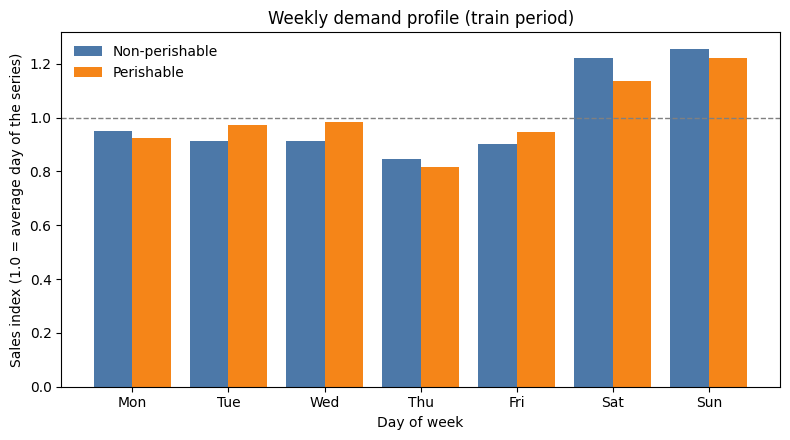

     Non-perishable  Perishable
Mon           0.949       0.924
Tue           0.915       0.973
Wed           0.913       0.984
Thu           0.847       0.817
Fri           0.901       0.946
Sat           1.222       1.136
Sun           1.254       1.222


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

cols = ["store_nbr", "item_nbr", "unit_sales", "perishable", "dow", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]]

# each day's sales relative to the average day of the same series (1.0 = average day)
series_mean = tr.groupby(["store_nbr", "item_nbr"])["unit_sales"].transform("mean")
idx = (tr["unit_sales"] / series_mean).where(series_mean > 0)
tab = idx.groupby([tr["perishable"], tr["dow"]]).mean().unstack(0)
tab.columns = ["Non-perishable", "Perishable"]
tab.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

x = np.arange(7)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.2, tab["Non-perishable"], width=0.4, label="Non-perishable", color="#4C78A8")
ax.bar(x + 0.2, tab["Perishable"], width=0.4, label="Perishable", color="#F58518")
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xticks(x, tab.index)
ax.set_xlabel("Day of week")
ax.set_ylabel("Sales index (1.0 = average day of the series)")
ax.set_title("Weekly demand profile (train period)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig1_weekday_profile.png", dpi=150)
plt.show()
print(tab.round(3))

**Chart 1 – interpretation.** Demand follows a clear weekly cycle. Saturday and Sunday are 14% to 25% above the average day, and Thursday is the lowest day (index 0.82 to 0.85). Perishable products have a slightly lower weekend peak and flatter weekdays. The 7-day pattern supports a seasonal naive baseline with a weekly period.

### Chart 2: Average sales per active series-day by month (aggregate trend)

**Purpose.** Show how the average sales per active series change over time (2013 to mid-2017). This is an aggregate trend: it mixes changes in demand with changes in the product range, so it is read together with chart 2e.

**Method.** Train period, store open. Average sales per series-day for each month, separately for perishable and non-perishable products, each divided by its own period mean so that both can share one axis. A dotted line marks the April 2016 earthquake for reference.

**Output.** `figures/fig2_monthly_trend.png` and the index at five points in time.

**Limitation.** New series appear over time, so the mix of products changes. The subset contains no store in Manabí, the region hit hardest by the earthquake, so any effect here would be indirect.

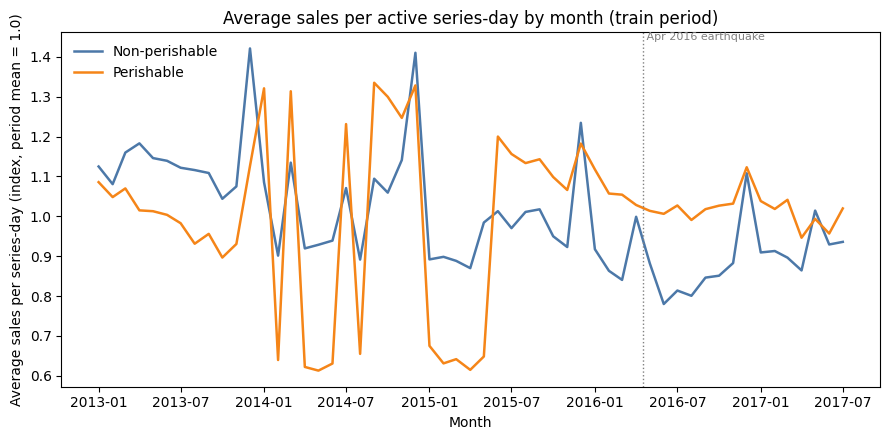

            Non-perishable  Perishable
month                                 
2013-01-01           1.125       1.086
2014-02-01           0.901       0.640
2015-04-01           0.870       0.615
2016-06-01           0.780       1.006
2017-07-01           0.936       1.020


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

cols = ["date", "unit_sales", "perishable", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]].copy()

# average sales per series-day by month, shown as an index so both groups share one axis
tr["month"] = tr["date"].dt.to_period("M").dt.to_timestamp()
m = tr.groupby(["month", "perishable"])["unit_sales"].mean().unstack()
m.columns = ["Non-perishable", "Perishable"]
m = m / m.mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
for c, color in zip(m.columns, ["#4C78A8", "#F58518"]):
    ax.plot(m.index, m[c], label=c, color=color, lw=1.8)
ax.axvline(pd.Timestamp("2016-04-16"), color="grey", ls=":", lw=1)
ax.text(pd.Timestamp("2016-04-16"), ax.get_ylim()[1], " Apr 2016 earthquake", va="top", fontsize=8, color="grey")
ax.set_xlabel("Month")
ax.set_ylabel("Average sales per series-day (index, period mean = 1.0)")
ax.set_title("Average sales per active series-day by month (train period)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "fig2_monthly_trend.png", dpi=150)
plt.show()
print(m.iloc[[0, len(m) // 4, len(m) // 2, 3 * len(m) // 4, -1]].round(3))

### Chart 2b: Is the monthly trend driven by extreme values?

**Purpose.** In chart 2 the perishable index swings far more in 2014 and 2015 than later. This step checks whether a few very large sales values, rather than a real trend, cause the swings.

**Method.** The monthly index is computed twice, with all rows and without the rows flagged `is_extreme` (above the 99.9th percentile of the family, threshold learned on train). The standard deviation of the index, the share of monthly sales coming from extreme rows and the number of active series per month are compared.

**Output.** `figures/fig2b_trend_without_extremes.png` and three small tables.

**Limitation.** The extreme rows are removed only for this check; the data do not show whether they are errors or genuine bulk sales, so they are not deleted from the dataset.

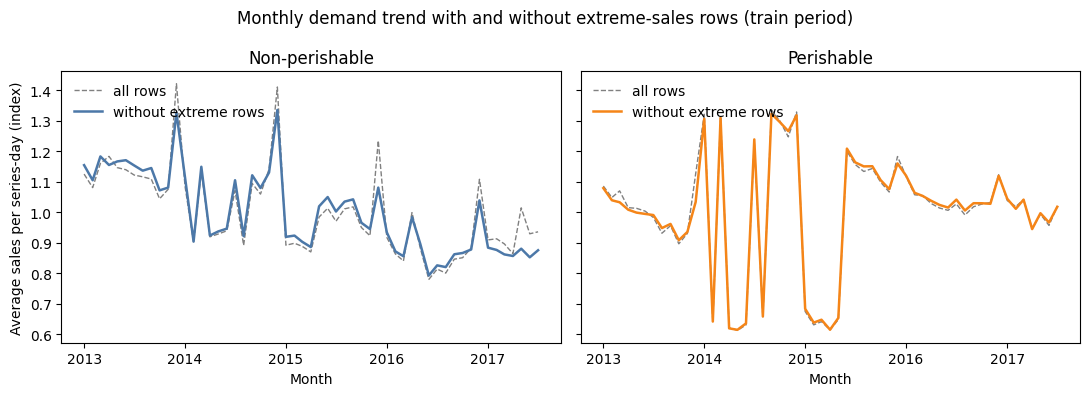

volatility of the monthly index (standard deviation):
                all rows  without extreme rows
Non-perishable     0.139                 0.132
Perishable         0.202                 0.199

perishable: months with the largest share of sales from extreme rows
            active_series  extreme_rows  extreme_share_of_sales_%
month                                                            
2013-12-01            526            49                      10.4
2013-03-01            401            41                       5.8
2015-12-01            992            51                       4.1
2013-05-01            412            18                       3.6
2014-01-01            756            38                       3.4
2014-09-01            817            48                       3.2
2013-06-01            415            23                       3.1
2013-02-01            394            18                       3.1

perishable: active series per month (first, middle, last)
month
2013-01-01

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

cols = ["store_nbr", "item_nbr", "date", "unit_sales", "perishable", "split", "is_closed", "is_extreme"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]].copy()
tr["month"] = tr["date"].dt.to_period("M").dt.to_timestamp()
tr["key"] = tr["store_nbr"].astype("int64") * 10_000_000 + tr["item_nbr"].astype("int64")

# monthly mean sales per series-day, with and without the extreme-sales rows
raw = tr.groupby(["month", "perishable"])["unit_sales"].mean().unstack()
clean = tr[~tr["is_extreme"]].groupby(["month", "perishable"])["unit_sales"].mean().unstack()
raw.columns = clean.columns = ["Non-perishable", "Perishable"]
raw, clean = raw / raw.mean(), clean / clean.mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, c, color in zip(axes, raw.columns, ["#4C78A8", "#F58518"]):
    ax.plot(raw.index, raw[c], color="grey", ls="--", lw=1, label="all rows")
    ax.plot(clean.index, clean[c], color=color, lw=1.8, label="without extreme rows")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(c)
    ax.set_xlabel("Month")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Average sales per series-day (index)")
fig.suptitle("Monthly demand trend with and without extreme-sales rows (train period)")
fig.tight_layout()
fig.savefig(FIG / "fig2b_trend_without_extremes.png", dpi=150)
plt.show()

print("volatility of the monthly index (standard deviation):")
print(pd.DataFrame({"all rows": raw.std(), "without extreme rows": clean.std()}).round(3))

per = tr[tr["perishable"] == 1]
tot = per.groupby("month")["unit_sales"].sum()
ext = per[per["is_extreme"]].groupby("month")["unit_sales"].sum().reindex(tot.index).fillna(0)
diag = pd.DataFrame({"active_series": per.groupby("month")["key"].nunique(),
                     "extreme_rows": per.groupby("month")["is_extreme"].sum(),
                     "extreme_share_of_sales_%": ext / tot * 100})
print("\nperishable: months with the largest share of sales from extreme rows")
print(diag.sort_values("extreme_share_of_sales_%", ascending=False).head(8).round(1).to_string())
print("\nperishable: active series per month (first, middle, last)")
print(diag["active_series"].iloc[[0, len(diag) // 2, -1]].to_string())

**Chart 2b – interpretation.** Removing the rows flagged as extreme barely changes the monthly index: its standard deviation moves from 0.202 to 0.199 for perishable products and from 0.139 to 0.132 for non-perishable products. Extreme rows account for at most 10.4% of monthly perishable sales (December 2013) and usually about 3%, so they do not explain the swings.

### Chart 2c: Which series drive the monthly swings?

**Purpose.** Removing extreme rows (chart 2b) did not calm the perishable trend, so the swings must come from somewhere else. This step tests whether a few very large series dominate the monthly average.

**Method.** For perishable products (train period, store open): list the ten series with the most sales; build the monthly index three ways (plain mean per series-day, mean without the five largest series, and the mean of a per-series index where each series is divided by its own average, so every series has the same weight regardless of its volume; this does not remove the effect of products entering or leaving the range, see chart 2e); compare the volatility of the three lines; and show how much of the monthly sales comes from the top five series in the lowest and highest months.

**Output.** `figures/fig2c_perishable_trend_methods.png` and three tables.

**Limitation.** If a large series is missing in some months, the data cannot tell whether it was out of stock, not stocked or not recorded. The per-series index describes the typical product rather than total sales.

top 10 perishable series by total sales:
            family  store     item          total  months  share_of_total_%
key                                                                        
441473428  PRODUCE     44  1473428  134913.593750      43               1.2
491473428  PRODUCE     49  1473428  134726.000000      43               1.2
110760319  POULTRY     11   760319  120473.796875      55               1.1
440159156  POULTRY     44   159156  120026.703125      55               1.1
441625605  PRODUCE     44  1625605  118757.398438      43               1.1
440557256     EGGS     44   557256  116886.000000      55               1.0
441695845  PRODUCE     44  1695845  111045.000000      43               1.0
491625605  PRODUCE     49  1625605  105965.500000      43               0.9
441083152    DAIRY     44  1083152   93996.000000      55               0.8
490557256     EGGS     49   557256   89571.000000      55               0.8


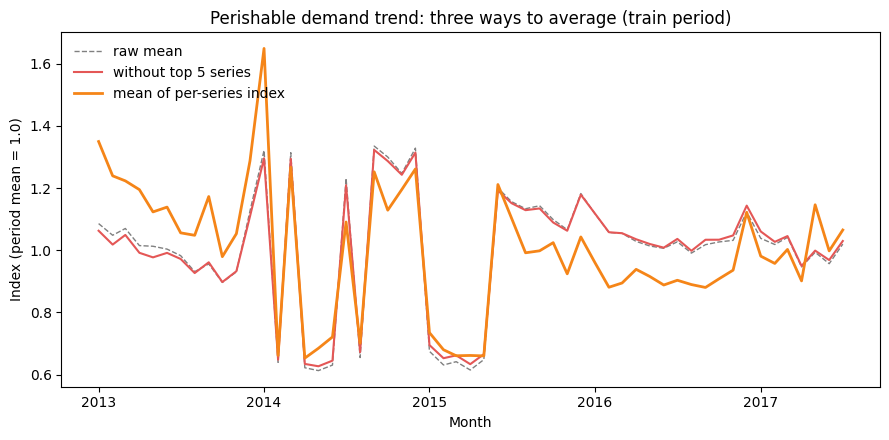


volatility of the monthly index (standard deviation):
raw mean                    0.202
without top 5 series        0.193
mean of per-series index    0.208

5 lowest and 5 highest months of the raw index, with the share of sales from the top 5 series:
            raw_index  top5_share_of_sales_%
month                                       
2014-05-01       0.61                   3.89
2015-04-01       0.62                   3.02
2014-04-01       0.62                   4.14
2014-06-01       0.63                   3.90
2015-02-01       0.63                   2.65
2014-10-01       1.30                   6.86
2014-03-01       1.31                   7.35
2014-01-01       1.32                   7.78
2014-12-01       1.33                   6.91
2014-09-01       1.34                   6.80
median month share: 5.6 %


In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
TOP_K = 5

cols = ["store_nbr", "item_nbr", "date", "unit_sales", "family", "perishable", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
per = df[df["split"].eq("train") & ~df["is_closed"] & df["perishable"].eq(1)].copy()
per["family"] = per["family"].astype(str)
per["month"] = per["date"].dt.to_period("M").dt.to_timestamp()
per["key"] = per["store_nbr"].astype("int64") * 10_000_000 + per["item_nbr"].astype("int64")

# 1) which series carry the volume
by_series = per.groupby("key").agg(family=("family", "first"), store=("store_nbr", "first"),
                                   item=("item_nbr", "first"), total=("unit_sales", "sum"),
                                   months=("month", "nunique"))
by_series["share_of_total_%"] = by_series["total"] / by_series["total"].sum() * 100
top = by_series.sort_values("total", ascending=False).head(10)
print("top 10 perishable series by total sales:")
print(top.round(1).to_string())
top_keys = top.index[:TOP_K]

# 2) three ways to build the monthly index
raw = per.groupby("month")["unit_sales"].mean()
no_top = per[~per["key"].isin(top_keys)].groupby("month")["unit_sales"].mean()
series_mean = per.groupby("key")["unit_sales"].transform("mean")
norm = (per["unit_sales"] / series_mean).where(series_mean > 0).groupby(per["month"]).mean()
lines = pd.DataFrame({"raw mean": raw / raw.mean(),
                      f"without top {TOP_K} series": no_top / no_top.mean(),
                      "mean of per-series index": norm / norm.mean()})

fig, ax = plt.subplots(figsize=(9, 4.5))
styles = {"raw mean": ("grey", "--", 1), f"without top {TOP_K} series": ("#E45756", "-", 1.5),
          "mean of per-series index": ("#F58518", "-", 2)}
for c in lines.columns:
    color, ls, lw = styles[c]
    ax.plot(lines.index, lines[c], label=c, color=color, ls=ls, lw=lw)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Month")
ax.set_ylabel("Index (period mean = 1.0)")
ax.set_title("Perishable demand trend: three ways to average (train period)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "fig2c_perishable_trend_methods.png", dpi=150)
plt.show()

print("\nvolatility of the monthly index (standard deviation):")
print(lines.std().round(3).to_string())

# 3) how concentrated are the lowest and highest months
share_top = (per[per["key"].isin(top_keys)].groupby("month")["unit_sales"].sum()
             / per.groupby("month")["unit_sales"].sum() * 100).fillna(0)
order = lines["raw mean"].sort_values()
summary = pd.DataFrame({"raw_index": order, f"top{TOP_K}_share_of_sales_%": share_top.reindex(order.index)})
print(f"\n5 lowest and 5 highest months of the raw index, with the share of sales from the top {TOP_K} series:")
print(pd.concat([summary.head(5), summary.tail(5)]).round(2).to_string())
print("median month share:", round(share_top.median(), 1), "%")

**Chart 2c – interpretation.** Perishable sales are not concentrated in a few series: each of the ten largest series has 0.8% to 1.2% of total sales, and the five largest together account for a median of 5.6% of monthly sales (3% to 4% in the lowest months). The index swings by about the same amount when all series are used (standard deviation 0.202), when the five largest are removed (0.193) and when every series has equal weight (0.208), so the swings are not caused by a few large products.

### Chart 2d: Frequency of sales versus size of sales

**Purpose.** Chart 2c showed that almost all perishable series fall and rise together in 2014 and 2015, so the swings are not caused by a few large products. This step splits the monthly average into how often products sell and how much they sell when they do.

**Method.** For perishable products (train period, store open), monthly mean sales per series-day is written as the share of days with a sale multiplied by the average units on days with a sale. Both parts are plotted as indices, and their correlation with the monthly mean is printed. Two low months (May 2014, April 2015) and two normal months are compared, also store by store.

**Output.** `figures/fig2d_frequency_vs_size.png` and three tables.

**Limitation.** The data show that sales were not recorded on those days, not why. A missing record can mean no demand, an empty shelf or a reporting gap, and the dataset cannot separate them.

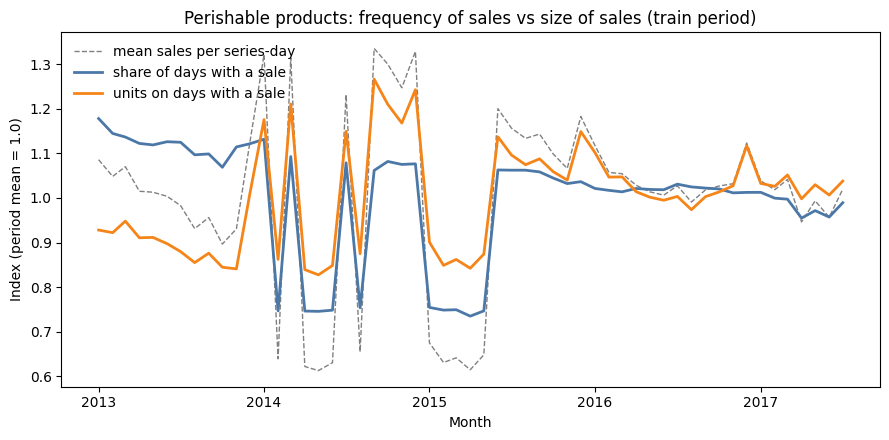

correlation of the monthly mean with each component:
share_days_with_sale    0.84
units_when_selling      0.87

comparison months (two low, two normal):
            raw_mean  share_days_with_sale  units_when_selling  active_series
month                                                                        
2013-05-01     8.366                 0.795              10.527            412
2014-05-01     5.064                 0.530               9.557            681
2015-04-01     5.080                 0.522               9.728            855
2016-05-01     8.374                 0.724              11.568           1009

share of days with a sale, by store:
           2013-05  2014-05  2015-04  2016-05
store_nbr                                    
10            0.72     0.49     0.46     0.53
11            0.70     0.44     0.48     0.64
24            0.85      NaN     0.55     0.81
26            0.66     0.45     0.45     0.51
28            0.78     0.49     0.51     0.72
30            0.66 

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
COMPARE = pd.to_datetime(["2013-05-01", "2014-05-01", "2015-04-01", "2016-05-01"])  # two dips, two normal months

cols = ["store_nbr", "item_nbr", "date", "unit_sales", "perishable", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
per = df[df["split"].eq("train") & ~df["is_closed"] & df["perishable"].eq(1)].copy()
per["month"] = per["date"].dt.to_period("M").dt.to_timestamp()
per["key"] = per["store_nbr"].astype("int64") * 10_000_000 + per["item_nbr"].astype("int64")
per["has_sale"] = per["unit_sales"] > 0

# mean sales = (share of days with a sale) x (units on a day with a sale)
m = pd.DataFrame({
    "raw_mean": per.groupby("month")["unit_sales"].mean(),
    "share_days_with_sale": per.groupby("month")["has_sale"].mean(),
    "units_when_selling": per[per["has_sale"]].groupby("month")["unit_sales"].mean(),
    "active_series": per.groupby("month")["key"].nunique(),
})
rel = m[["raw_mean", "share_days_with_sale", "units_when_selling"]] / m[["raw_mean", "share_days_with_sale", "units_when_selling"]].mean()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rel.index, rel["raw_mean"], color="grey", ls="--", lw=1, label="mean sales per series-day")
ax.plot(rel.index, rel["share_days_with_sale"], color="#4C78A8", lw=2, label="share of days with a sale")
ax.plot(rel.index, rel["units_when_selling"], color="#F58518", lw=2, label="units on days with a sale")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Month")
ax.set_ylabel("Index (period mean = 1.0)")
ax.set_title("Perishable products: frequency of sales vs size of sales (train period)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "fig2d_frequency_vs_size.png", dpi=150)
plt.show()

print("correlation of the monthly mean with each component:")
print(rel.corr().loc["raw_mean", ["share_days_with_sale", "units_when_selling"]].round(2).to_string())
print("\ncomparison months (two low, two normal):")
print(m.loc[m.index.isin(COMPARE)].round(3).to_string())

sel = per[per["month"].isin(COMPARE)]
by_store = sel.groupby(["store_nbr", "month"])["has_sale"].mean().unstack().round(2)
by_store.columns = [c.strftime("%Y-%m") for c in by_store.columns]
print("\nshare of days with a sale, by store:")
print(by_store.to_string())

**Chart 2d – interpretation.** In the low months of 2014 and 2015 almost every store sells on about 30% fewer days (for example store 10: 72% to 49%; store 44: 94% to 64%), while sales on selling days fall only slightly (10.5 to 9.6 units).The monthly mean follows both parts (correlation 0.84 with frequency and 0.87 with size), so the correlations alone do not show which part matters more. Between May 2013 and May 2014 the monthly mean falls by 39%, of which the share of days with a sale falls by 33% and the units on selling days by 9%, so the drop is mostly a drop in frequency.

### Chart 2e: Like-for-like trend (main trend chart)

**Purpose.** Separate two questions that the monthly average mixes together: how the average sales of the active products change when the product range changes (aggregate trend), and how demand for the same products changes over time (like-for-like trend). This is the main trend chart; charts 2b to 2d are supporting checks and 2f explains where the differences come from.

**Method.** Train period, store open. Each day's sales are divided by the average of the same series, so 1.0 means the series' own average and differences in scale and units are removed. The monthly average of this index is shown for all active series (dashed) and for continuing series only (solid), i.e. series whose first sale was on or before 31 January 2013 (1,431 non-perishable and 389 perishable series). The printed table gives the share of continuing series among the active ones.

**Output.** `figures/fig2e_like_for_like.png` and one table per product group.

**Limitation.** Continuing series are a selected group: products sold from the start, including those that were later phased out (their zero-filled days stay in the index). Single months in the table are not adjusted for seasonality, so differences between months partly reflect the season.

Non-perishable: 3,728 series, of which continuing: 1,431
Perishable: 1,111 series, of which continuing: 389


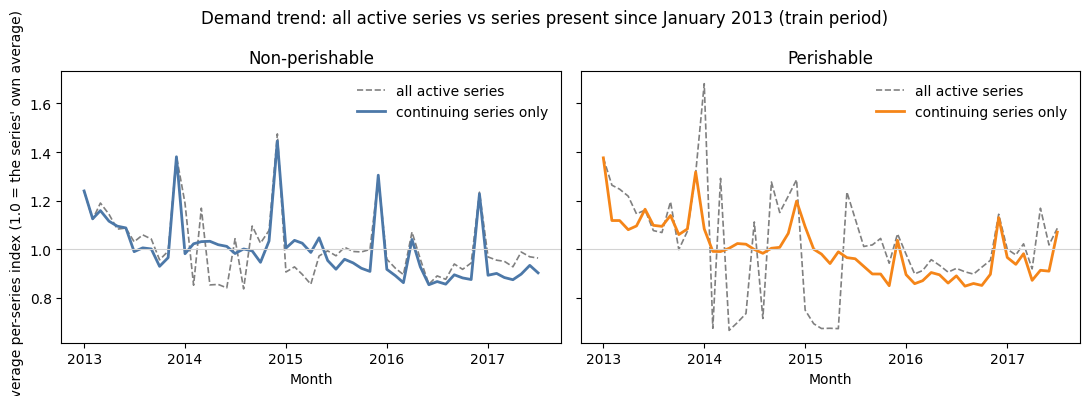


Non-perishable:
            all_series  continuing  continuing_share_of_active
month                                                         
2013-01-01       1.240       1.240                       1.000
2014-02-01       0.852       1.022                       0.625
2015-04-01       0.856       0.987                       0.546
2016-06-01       0.856       0.854                       0.436
2017-07-01       0.964       0.903                       0.384

Perishable:
            all_series  continuing  continuing_share_of_active
month                                                         
2013-01-01       1.376       1.376                       1.000
2014-02-01       0.675       0.991                       0.515
2015-04-01       0.675       0.941                       0.455
2016-06-01       0.906       0.861                       0.385
2017-07-01       1.086       1.071                       0.350

December index, continuing non-perishable series:
date
2013    1.38
2014    1.45
2015  

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
START_BY = "2013-01-31"     # continuing series: first sale on or before this date

cols = ["store_nbr", "item_nbr", "date", "unit_sales", "perishable", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]].copy()
tr["month"] = tr["date"].dt.to_period("M").dt.to_timestamp()
tr["key"] = tr["store_nbr"].astype("int64") * 10_000_000 + tr["item_nbr"].astype("int64")

first = tr.groupby("key")["date"].transform("min")
tr["continuing"] = first <= pd.Timestamp(START_BY)
smean = tr.groupby("key")["unit_sales"].transform("mean")
tr["idx"] = (tr["unit_sales"] / smean).where(smean > 0)      # 1.0 = the series' own average

groups = {0: "Non-perishable", 1: "Perishable"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
summary = {}
for ax, (flag, name) in zip(axes, groups.items()):
    g = tr[tr["perishable"] == flag]
    all_s = g.groupby("month")["idx"].mean()
    cont = g[g["continuing"]].groupby("month")["idx"].mean()
    share = (g[g["continuing"]].groupby("month")["key"].nunique() / g.groupby("month")["key"].nunique())
    ax.plot(all_s.index, all_s, color="grey", ls="--", lw=1.2, label="all active series")
    ax.plot(cont.index, cont, color="#4C78A8" if flag == 0 else "#F58518", lw=2, label="continuing series only")
    ax.axhline(1, color="lightgrey", lw=0.8)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(name)
    ax.set_xlabel("Month")
    ax.legend(frameon=False, loc="upper right")
    pts = [0, len(cont) // 4, len(cont) // 2, 3 * len(cont) // 4, len(cont) - 1]
    summary[name] = pd.DataFrame({"all_series": all_s.iloc[pts], "continuing": cont.iloc[pts],
                                  "continuing_share_of_active": share.iloc[pts]})
    print(f"{name}: {g['key'].nunique():,} series, of which continuing: {g.loc[g['continuing'], 'key'].nunique():,}")
axes[0].set_ylabel("Average per-series index (1.0 = the series' own average)")
fig.suptitle("Demand trend: all active series vs series present since January 2013 (train period)")
fig.tight_layout()
fig.savefig(FIG / "fig2e_like_for_like.png", dpi=150)
plt.show()
for name, t in summary.items():
    print(f"\n{name}:")
    print(t.round(3).to_string())

dec = tr[(tr["perishable"] == 0) & tr["continuing"] & (tr["date"].dt.month == 12)]
print("\nDecember index, continuing non-perishable series:")
print(dec.groupby(dec["date"].dt.year)["idx"].mean().round(2).to_string())

**Chart 2e – interpretation.** The swings of the perishable trend in 2014 and 2015 do not appear among the 389 perishable series that were sold from January 2013: their index declines smoothly from about 1.0 in February 2014 to 0.86 in mid-2016 and recovers to about 1.07 in 2017 (January 2013 is left out because every series starts with a sale, which inflates the first month). The swings come from changes in the product range, not from changes in the sales of existing products: 43% of all new perishable series were first sold in November 2013 and January 2014 (chart 2f), and by July 2017 only 35% of the active perishable series (38% of the non-perishable) were present in 2013. Among non-perishable products the continuing series also decline, by roughly 10% to 15% between 2013-2014 and 2016-2017 (single months, not adjusted for season), so the lower level is not only an effect of new products. Part of the decline may come from products that were gradually phased out. The continuing non-perishable series peak every December (index 1.38, 1.45, 1.30 and 1.23 in 2013 to 2016, that is 23% to 45% above their own average), and the peak has been lower each year since 2014.

### Chart 2f: Do product launches explain the swings?

**Purpose.** Chart 2e shows that the swings in the perishable trend disappear when only series present since January 2013 are kept. This step checks the mechanism: whether new products entered in waves and sold less in their first months.

**Method.** (1) Count the perishable series by the month of their first sale (after January 2013). (2) For all series first sold after January 2013, average sales relative to the series' own average, by months since the first sale.

**Output.** `figures/fig2f_launches.png`, the busiest launch months and a table by age.

**Limitation.** A first sale in the data is not necessarily the product launch: it may also be the first time the product was stocked or recorded in these stores.

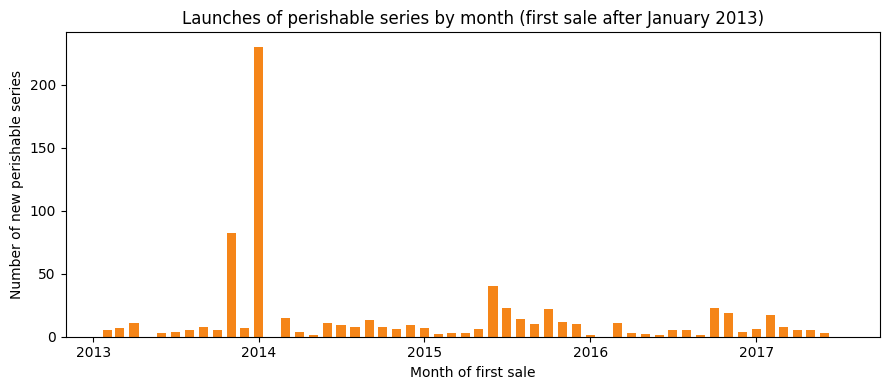

months with the most new perishable series:
month
2014-01-01    230
2013-11-01     82
2015-06-01     40
2015-07-01     23
2016-10-01     23
2015-10-01     22

new perishable series: 722; in the 6 busiest months: 58%

average per-series index by months since first sale (12 = 12 months or more):
            Non-perishable  Perishable
age_months                            
0                     1.79        3.40
1                     0.92        0.68
2                     1.09        1.00
3                     0.82        0.57
4                     0.79        0.55
5                     0.82        0.63
6                     1.02        1.08
7                     0.81        0.59
8                     1.01        1.09
9                     1.04        1.10
10                    1.00        1.01
11                    1.06        0.99
12                    0.99        0.96


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
START_BY = pd.Timestamp("2013-01-31")      # series first sold on or before this date are the initial range

cols = ["store_nbr", "item_nbr", "date", "unit_sales", "perishable", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]].copy()
tr["key"] = tr["store_nbr"].astype("int64") * 10_000_000 + tr["item_nbr"].astype("int64")

first = tr.groupby("key").agg(first_date=("date", "min"), perishable=("perishable", "first"))
new = first[first["first_date"] > START_BY].copy()
new["month"] = new["first_date"].dt.to_period("M").dt.to_timestamp()
launches = new.groupby(["month", "perishable"]).size().unstack(fill_value=0)
launches.columns = ["Non-perishable", "Perishable"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(launches.index, launches["Perishable"], width=20, color="#F58518")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Month of first sale")
ax.set_ylabel("Number of new perishable series")
ax.set_title("Launches of perishable series by month (first sale after January 2013)")
fig.tight_layout()
fig.savefig(FIG / "fig2f_launches.png", dpi=150)
plt.show()

top = launches["Perishable"].sort_values(ascending=False).head(6)
print("months with the most new perishable series:")
print(top.to_string())
print(f"\nnew perishable series: {int(launches['Perishable'].sum()):,}; "
      f"in the 6 busiest months: {top.sum() / launches['Perishable'].sum():.0%}")

# early life: sales relative to the series' own average, by months since first sale
tr = tr.merge(first["first_date"], left_on="key", right_index=True)
smean = tr.groupby("key")["unit_sales"].transform("mean")
tr["idx"] = (tr["unit_sales"] / smean).where(smean > 0)
n = tr[tr["first_date"] > START_BY].copy()
n["age_months"] = ((n["date"] - n["first_date"]).dt.days // 30).clip(upper=12)
early = n.groupby(["age_months", "perishable"])["idx"].mean().unstack()
early.columns = ["Non-perishable", "Perishable"]
print("\naverage per-series index by months since first sale (12 = 12 months or more):")
print(early.round(2).to_string())

**Chart 2f – interpretation.** Launches of perishable series are concentrated in a few months: 230 of the 722 new series (32%) were first sold in January 2014 and 82 in November 2013 (43% together), with a smaller wave of 40 in June 2015. In their first month new series show an index of 3.4 (perishable) and 1.8 (non-perishable), but this figure is inflated: each series is divided by its own average over its whole life, which includes zero-filled days after a product stops selling, so short-lived series have a small denominator and a very high first-month value. The data therefore do not show whether new series start slowly; this would need an index based on the active period only, or the median instead of the mean. The later months are uneven (index between 0.55 and 1.1) and follow the calendar pattern of chart 2, because the January 2014 wave dominates the table. A first sale in the data is not necessarily a product launch; it may be the first time the product was stocked or recorded.

**Chart 2 – interpretation.** Average sales per active series-day fall for non-perishable products from about 1.1 in 2013 to 0.78–0.94 in 2016–2017, and for perishable products they swing between about 0.6 and 1.3 during 2014 and 2015 before settling. These are aggregate figures that mix changes in demand with changes in the product range, so they are read together with chart 2e. Among the perishable series sold since January 2013 the trend is smooth, and 43% of all new perishable series (312 of 722) were first sold in two months, November 2013 and January 2014. The swings therefore reflect these launch waves rather than changes in the sales of existing products (charts 2e and 2f). Why the new series sell so unevenly in their first year cannot be determined from the data. The validation and test periods (2017) are not affected.

### Chart 3: Sales on paydays compared with other days

**Purpose.** Compare sales on paydays (the 15th and the last day of the month) with other days, and check whether the difference is the same for perishable and non-perishable products.

**Method.** Train period, store open. Each day's sales are divided by the average of the same series on the same weekday, so that weekday patterns do not blur the comparison. The bar is the percentage difference between payday and other days, per year and product group. Showing each year checks whether the difference is stable. Paydays follow a calendar rule that assumes the usual pay schedule; it is not a verified payroll calendar.

**Output.** `figures/fig3_payday_effect.png` and the table of percentages.

**Limitation.** This is an association, not proof of a cause. Paydays also coincide with month-end ordering and with local holidays. 2017 contains only part of the year.

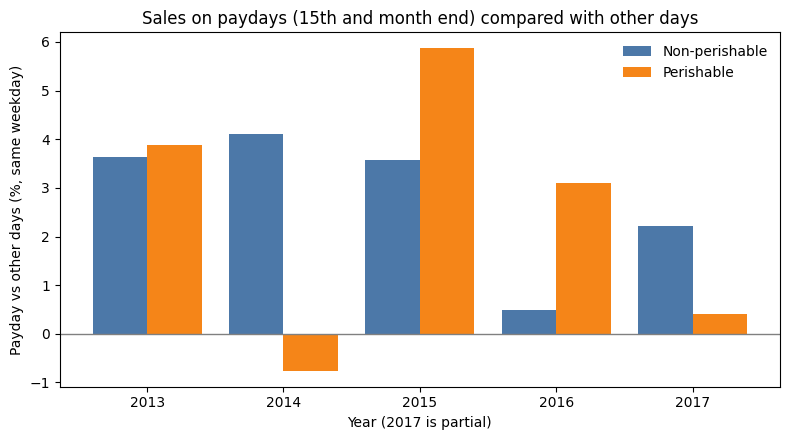

      Non-perishable  Perishable
year                            
2013            3.63        3.89
2014            4.10       -0.76
2015            3.58        5.87
2016            0.50        3.09
2017            2.22        0.41


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

cols = ["store_nbr", "item_nbr", "date", "unit_sales", "perishable", "dow", "is_payday", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)
tr = df[df["split"].eq("train") & ~df["is_closed"]].copy()

# sales relative to the same series on the same weekday, so weekday effects do not blur the comparison
ref = tr.groupby(["store_nbr", "item_nbr", "dow"])["unit_sales"].transform("mean")
tr["idx"] = (tr["unit_sales"] / ref).where(ref > 0)
tr["year"] = tr["date"].dt.year

g = tr.groupby(["perishable", "year", "is_payday"])["idx"].mean().unstack("is_payday")
lift = ((g[1] / g[0] - 1) * 100).unstack("perishable")
lift.columns = ["Non-perishable", "Perishable"]

x = np.arange(len(lift))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.2, lift["Non-perishable"], width=0.4, label="Non-perishable", color="#4C78A8")
ax.bar(x + 0.2, lift["Perishable"], width=0.4, label="Perishable", color="#F58518")
ax.axhline(0, color="grey", lw=1)
ax.set_xticks(x, lift.index)
ax.set_xlabel("Year (2017 is partial)")
ax.set_ylabel("Payday vs other days (%, same weekday)")
ax.set_title("Sales on paydays (15th and month end) compared with other days")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig3_payday_effect.png", dpi=150)
plt.show()
print(lift.round(2))

**Chart 3 – interpretation.** Sales are only slightly higher on paydays, and not consistently. The difference from other days of the same weekday is between 0.5% and 4.1% for non-perishable products and between -0.8% and 5.9% for perishable products, and it changes from year to year (nine of the ten values are positive). There is no clear difference between the two groups, so the data show at most a weak association between paydays and sales. Paydays are defined by a calendar rule (the 15th and the last day of the month), an assumed pay schedule.

### Chart 4: Promotion lift by product family

**Purpose.** Measure how much higher sales are on promotion days, and in which families the difference is largest.

**Method.** Train period, store open, only rows where a promotion value was recorded. This value is recorded only on days with sales and only from April 2014, so every row compared here has sales. Each row is divided by the average of the same series on the same weekday. The bar is the percentage difference between promotion and non-promotion rows per family; families with fewer than 500 promotion rows are not shown.

**Output.** `figures/fig4_promotion_lift.png` and the table of lifts and row counts.

**Limitation.** (1) Because zero-sales days have no promotion record, this measures the size of sales given a sale, not whether a sale happens. (2) Promotions are chosen, not random, so the lift is an association rather than a causal effect. (3) Units are mixed (items and kilograms), handled through the within-series index.

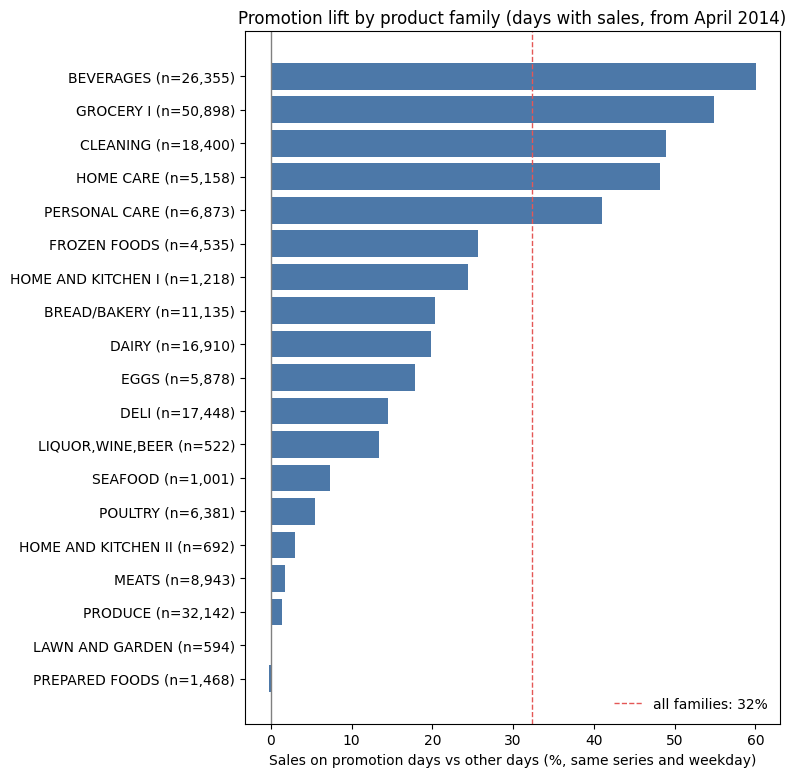

overall lift: 32.3% | rows with promotion: 218,225 of 2,973,753
                     lift_pct  promo_rows
family                                   
PREPARED FOODS           -0.2        1468
LAWN AND GARDEN          -0.0         594
PRODUCE                   1.4       32142
MEATS                     1.8        8943
HOME AND KITCHEN II       3.0         692
POULTRY                   5.4        6381
SEAFOOD                   7.3        1001
LIQUOR,WINE,BEER         13.4         522
DELI                     14.5       17448
EGGS                     17.8        5878
DAIRY                    19.9       16910
BREAD/BAKERY             20.3       11135
HOME AND KITCHEN I       24.5        1218
FROZEN FOODS             25.7        4535
PERSONAL CARE            41.0        6873
HOME CARE                48.2        5158
CLEANING                 48.9       18400
GROCERY I                54.9       50898
BEVERAGES                60.0       26355


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
MIN_PROMO_ROWS = 500       # families with fewer promotion rows are not shown

cols = ["store_nbr", "item_nbr", "unit_sales", "family", "dow", "onpromotion", "split", "is_closed"]
df = pd.read_parquet(BASE / "features" / "subset_model.parquet", columns=cols)

# only rows where a promotion value was recorded (recorded only on days with sales, from April 2014)
tr = df[df["split"].eq("train") & ~df["is_closed"] & (df["onpromotion"] >= 0) & (df["unit_sales"] > 0)].copy()
tr["family"] = tr["family"].astype(str)

ref = tr.groupby(["store_nbr", "item_nbr", "dow"])["unit_sales"].transform("mean")
tr["idx"] = (tr["unit_sales"] / ref).astype("float64")
g = tr.groupby(["family", "onpromotion"])["idx"].agg(["mean", "size"]).unstack("onpromotion")
res = pd.DataFrame({"lift_pct": (g[("mean", 1)] / g[("mean", 0)] - 1) * 100,
                    "promo_rows": g[("size", 1)]}).dropna()
res = res[res["promo_rows"] >= MIN_PROMO_ROWS].sort_values("lift_pct")
overall = (tr.loc[tr["onpromotion"] == 1, "idx"].mean() / tr.loc[tr["onpromotion"] == 0, "idx"].mean() - 1) * 100

labels = [f"{f} (n={int(n):,})" for f, n in zip(res.index, res["promo_rows"])]
fig, ax = plt.subplots(figsize=(8, 0.32 * len(res) + 1.8))
ax.barh(labels, res["lift_pct"], color="#4C78A8")
ax.axvline(0, color="grey", lw=1)
ax.axvline(overall, color="#E45756", ls="--", lw=1, label=f"all families: {overall:.0f}%")
ax.set_xlabel("Sales on promotion days vs other days (%, same series and weekday)")
ax.set_title("Promotion lift by product family (days with sales, from April 2014)")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "fig4_promotion_lift.png", dpi=150)
plt.show()
print(f"overall lift: {overall:.1f}% | rows with promotion: {int((tr['onpromotion'] == 1).sum()):,} of {len(tr):,}")
print(res.round(1).to_string())

**Chart 4 – interpretation.** On days with a recorded promotion, sales are 32% higher on average, but the size of the difference depends strongly on the product. Packaged goods show the largest differences (beverages +60%, grocery +55%, cleaning +49%, home care +48%, personal care +41%), while fresh products show little (meats +1.8%, produce +1.4%, prepared foods -0.2%) and dairy, bakery and eggs sit in between (about +18% to +20%). A possible explanation is that shelf-stable goods can be stocked up while fresh goods are bought for immediate use; this is a hypothesis the data cannot confirm. Promotions are chosen rather than random, so these differences are associations, not causal effects.

## 2. Demand classes and ABC-XYZ (charts 5 to 7)

How the store-item series differ in demand pattern and in contribution to sales. All profiles use the train period (store open). The cut-offs for ADI, CV² and ABC-XYZ are described in section 1.

### Chart 5: ADI vs CV² (demand classification)

**Purpose.** Show how store-item series split into smooth, erratic, intermittent and lumpy demand.

**Method.** Each point is one series (train period, store open). Dashed lines mark the Syntetos–Boylan cut-offs (ADI 1.32, CV² 0.49). Both axes are logarithmic; CV² values below 0.01 are drawn at 0.01.

**Output.** `figures/fig5_adi_cv2.png`.

**Limitation.** Zeros added to the grid may be stock-outs, so ADI may be overstated.

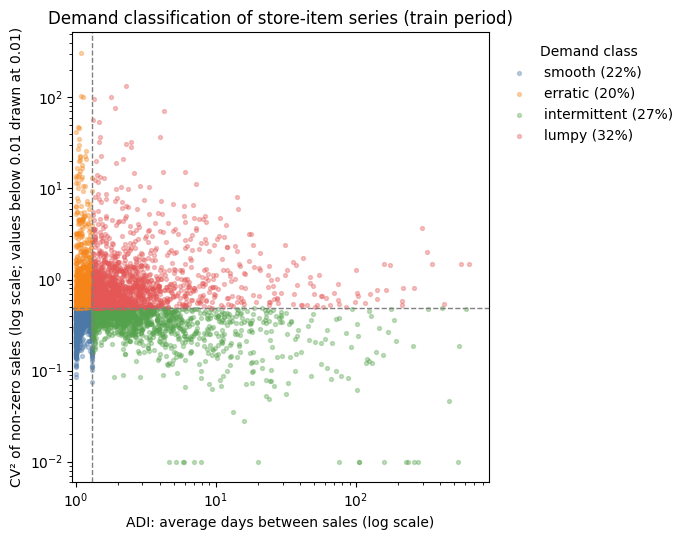

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

ADI_CUT, CV2_CUT = 1.32, 0.49
ORDER = ["smooth", "erratic", "intermittent", "lumpy"]
COLORS = {"smooth": "#4C78A8", "erratic": "#F58518", "intermittent": "#54A24B", "lumpy": "#E45756"}

prof = pd.read_parquet(BASE / "features" / "series_profile.parquet")
cl = prof[prof["demand_class"] != "short history"]

fig, ax = plt.subplots(figsize=(7, 5.5))
for k in ORDER:
    d = cl[cl["demand_class"] == k]
    ax.scatter(d["ADI"], d["CV2"].clip(lower=0.01), s=8, alpha=0.35, color=COLORS[k],
               label=f"{k} ({len(d) / len(cl):.0%})")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(left=0.95)
ax.axvline(ADI_CUT, color="grey", ls="--", lw=1)
ax.axhline(CV2_CUT, color="grey", ls="--", lw=1)
ax.set_xlabel("ADI: average days between sales (log scale)")
ax.set_ylabel("CV² of non-zero sales (log scale; values below 0.01 drawn at 0.01)")
ax.set_title("Demand classification of store-item series (train period)")
ax.legend(title="Demand class", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIG / "fig5_adi_cv2.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 5 – interpretation.** Only about one series in five (22%) is smooth. Close to six in ten are intermittent or lumpy, meaning they sell on fewer than roughly three days out of four. Erratic series sit almost on the ADI ≈ 1 line but reach CV² values in the hundreds, so a few very large sales dominate their variability.

### Chart 6: Demand class mix by product family

**Purpose.** Compare how regular or irregular demand is across product families.

**Method.** Share of series in each demand class per family, sorted by the share of intermittent and lumpy series. Families with fewer than 10 series are not shown; the number of series is printed next to each family name.

**Output.** `figures/fig6_class_by_family.png` and the five families with the lowest and highest share of irregular demand.

**Limitation.** Some families have few series in the subset, and units are mixed (items and kilograms), so classes are compared within a family rather than across families in absolute terms.

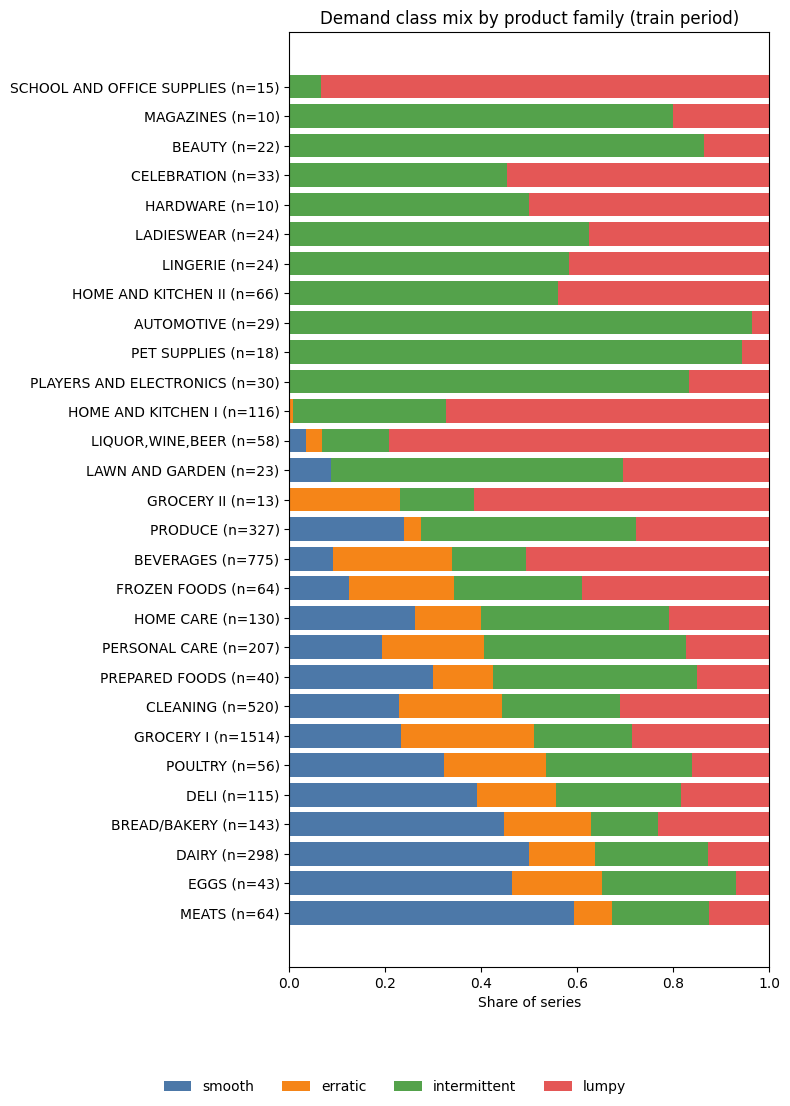

intermittent + lumpy share, lowest 5 families:
family
MEATS           0.328
EGGS            0.349
DAIRY           0.362
BREAD/BAKERY    0.371
DELI            0.443

intermittent + lumpy share, highest 5 families:
family
HARDWARE                      1.0
CELEBRATION                   1.0
BEAUTY                        1.0
MAGAZINES                     1.0
SCHOOL AND OFFICE SUPPLIES    1.0

families with 100% intermittent or lumpy: 11 of 29


In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

MIN_SERIES = 10            # families with fewer series are not shown
ORDER = ["smooth", "erratic", "intermittent", "lumpy"]
COLORS = {"smooth": "#4C78A8", "erratic": "#F58518", "intermittent": "#54A24B", "lumpy": "#E45756"}

prof = pd.read_parquet(BASE / "features" / "series_profile.parquet")
cl = prof[prof["demand_class"] != "short history"]

tab = cl.groupby(["family", "demand_class"]).size().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0)
tab = tab[tab.sum(axis=1) >= MIN_SERIES]
share = tab.div(tab.sum(axis=1), axis=0)
share = share.assign(_s=share["intermittent"] + share["lumpy"]).sort_values("_s")
irregular = share.pop("_s")
labels = [f"{f} (n={int(tab.loc[f].sum())})" for f in share.index]

fig, ax = plt.subplots(figsize=(8, 0.32 * len(share) + 1.8))
left = np.zeros(len(share))
for k in ORDER:
    ax.barh(labels, share[k], left=left, color=COLORS[k], label=k)
    left += share[k].to_numpy()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of series")
ax.set_title("Demand class mix by product family (train period)")
handles, names = ax.get_legend_handles_labels()
fig.legend(handles, names, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG / "fig6_class_by_family.png", dpi=150)
plt.show()

print("intermittent + lumpy share, lowest 5 families:")
print(irregular.head(5).round(3).to_string())
print("\nintermittent + lumpy share, highest 5 families:")
print(irregular.tail(5).round(3).to_string())
print("\nfamilies with 100% intermittent or lumpy:", int((irregular >= 0.999).sum()), "of", len(irregular))

**Chart 6 – interpretation.** Demand regularity depends on the product family. Staple foods (meats, eggs, dairy, bakery, deli) have the lowest share of intermittent or lumpy series (33% to 44%), while 11 of the 29 families shown, mostly non-food (e.g. hardware, beauty, magazines, school and office supplies), have 100%. Several of these families have fewer than 30 series, so their shares are less reliable. Produce is the exception among perishables (about 72% irregular), which is examined in chart 6b.

### Chart 6b: Why is produce irregular?

**Purpose.** Produce is perishable, yet chart 6 shows most of its series are intermittent or lumpy. This step checks what makes it differ from other perishable families such as dairy and meats.

**Method.** For selected families (train period, series with enough history), compare the share of days with a sale, the median ADI and CV², the median units sold on a selling day, and the share of intermittent and lumpy series.

**Output.** One table.

**Limitation.** The table describes the pattern but cannot prove the cause. Zeros added to the grid may be stock-outs rather than lack of demand, which would also make a family look intermittent.

In [41]:
import pandas as pd
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
prof = pd.read_parquet(BASE / "features" / "series_profile.parquet")
cl = prof[prof["demand_class"] != "short history"]

FOCUS = ["PRODUCE", "DAIRY", "MEATS", "EGGS", "BREAD/BAKERY", "BEVERAGES", "GROCERY I"]
d = cl[cl["family"].isin(FOCUS)]
g = d.groupby("family")

out = pd.DataFrame({
    "series": g.size(),
    "perishable": g["perishable"].max(),
    "share_of_days_with_sale": g["n_nonzero"].sum() / g["n_days"].sum(),
    "median_ADI": g["ADI"].median(),
    "median_CV2": g["CV2"].median(),
    "median_units_when_selling": g["mean_nz"].median(),
    "intermittent_%": g["demand_class"].apply(lambda s: (s == "intermittent").mean() * 100),
    "lumpy_%": g["demand_class"].apply(lambda s: (s == "lumpy").mean() * 100),
}).sort_values("share_of_days_with_sale")
print(out.round(2).to_string())

              series  perishable  share_of_days_with_sale  median_ADI  median_CV2  median_units_when_selling  intermittent_%  lumpy_%
family                                                                                                                               
PRODUCE          327           1                     0.57        1.44        0.41                       7.99           44.65    27.83
BEVERAGES        775           0                     0.63        1.51        0.69                       5.06           15.48    50.58
GROCERY I       1514           0                     0.72        1.31        0.53                       3.82           20.34    28.60
BREAD/BAKERY     143           1                     0.76        1.19        0.45                       5.49           13.99    23.08
MEATS             64           1                     0.76        1.14        0.40                       4.91           20.31    12.50
DAIRY            298           1                     0.79     

**Chart 6b – interpretation.** Perishability does not make demand regular. Produce is perishable but sells on only 57% of days, against 76% to 79% for dairy, eggs, meats and bakery, so 72% of its series are intermittent or lumpy. The cause is frequency, not size: its median CV² (0.41) is below the 0.49 cut-off, and units per selling day are not smaller (median 8.0 against 3.7 to 5.5; units are mixed because produce is often sold by weight). Beverages show a different mechanism: they sell on 63% of days but with the most variable sizes (median CV² 0.69), so half of their series are lumpy. Intermittency in produce may reflect stock availability rather than low demand, because the data cannot separate a day with no demand from a day with no stock.

### Chart 7: Quantity-based ABC and XYZ segmentation

**Purpose.** Show how much of the total quantity sold sits in each segment compared with how many series it contains.

**Method.** Two heatmaps from the series profile: share of series and share of the quantity sold. ABC is a quantity-based proxy: series are ranked by total units sold in the train period (items and kilograms are added together and there are no prices, so this is not revenue or value); A = series whose cumulative share of the quantity is at most 80%, B = up to 95%, C = the rest. XYZ is a descriptive diagnostic based on the variability of daily sales, including zero-filled days (CV below 0.5, below 1, otherwise).

**Output.** `figures/fig7_abc_xyz.png`.

**Limitation.** The XYZ thresholds were designed for weekly or monthly data; on daily sales almost no series reaches class X, so XYZ mainly separates Y from Z. XYZ does not replace ADI-CV², which answers a different question.

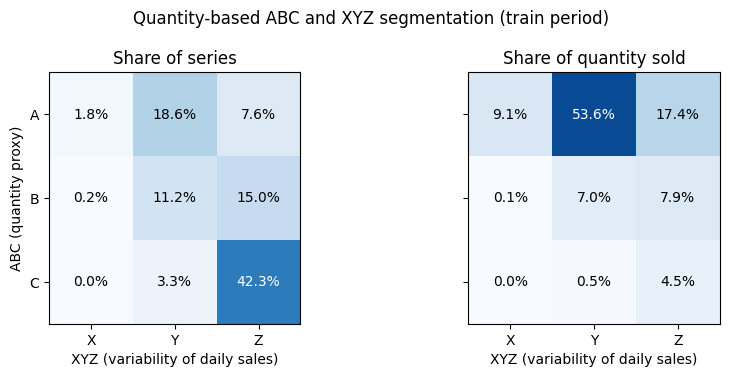

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path.home() / "Projects/bigdata"
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)

prof = pd.read_parquet(BASE / "features" / "series_profile.parquet")

idx, cols = list("ABC"), list("XYZ")
by_series = pd.crosstab(prof["ABC"], prof["XYZ"], normalize=True).reindex(index=idx, columns=cols, fill_value=0)
by_qty = (pd.crosstab(prof["ABC"], prof["XYZ"], values=prof["total_sales"], aggfunc="sum", normalize=True)
            .reindex(index=idx, columns=cols, fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, t, title in zip(axes, [by_series, by_qty], ["Share of series", "Share of quantity sold"]):
    ax.imshow(t.to_numpy(), cmap="Blues", vmin=0, vmax=0.6)
    ax.set_xticks(range(3), cols)
    ax.set_yticks(range(3), idx)
    for i in range(3):
        for j in range(3):
            v = t.iloc[i, j]
            ax.text(j, i, f"{v:.1%}", ha="center", va="center", color="white" if v > 0.3 else "black")
    ax.set_title(title)
    ax.set_xlabel("XYZ (variability of daily sales)")
axes[0].set_ylabel("ABC (quantity proxy)")
fig.suptitle("Quantity-based ABC and XYZ segmentation (train period)")
fig.tight_layout()
fig.savefig(FIG / "fig7_abc_xyz.png", dpi=150)
plt.show()

**Chart 7 – interpretation.** Volume is highly concentrated: group A is 28% of the series but 80% of the total quantity sold (items and kilograms are added together, so this is a volume proxy, not revenue), and segment AY alone holds 54% of it. At the other end, segment CZ is 42% of the series but only 4.5% of the quantity. Class X is almost empty (about 2% of series) because the CV cut-off of 0.5 is too strict for daily data.